In [56]:
# Install all necessary module packages for this assignment
%pip install pandas numpy
%pip install openpyxl
%pip install PyPortfolioOpt
%pip install openpyxl
%pip install adjustText
%pip install yfinance

# Import core data manipulation libraries
import pandas as pd
import numpy as np

# Import PyPortfolioOpt components for portfolio optimization
from pypfopt import (
    EfficientFrontier,  # Main class for mean-variance optimization
    risk_models,  # Functions to estimate covariance matrices
    expected_returns,  # Functions to estimate expected returns
)

# Import discrete allocation tools to convert weights to actual share counts
from pypfopt.discrete_allocation import DiscreteAllocation, get_latest_prices

# Import convex optimization library (used internally by PyPortfolioOpt)
import cvxpy as cp

# Import visualization library (ggplot-style grammar of graphics for Python)
from plotnine import *
from plotnine import options as p9_options
from mizani.formatters import percent_format  # Format axis labels as percentages

# Set default figure size for all plots
p9_options.figure_size = (8, 6)

# Configure pandas display options to show full outputs without truncation
pd.set_option("display.max_rows", None)  # Show all rows in output
pd.set_option("display.max_columns", None)  # Show all columns in output
pd.set_option("display.width", None)  # Auto-detect terminal width
pd.set_option("display.max_colwidth", None)  # Show full column content

6529.87s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


6535.64s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


6541.31s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


... (2 outputs left out)

6552.77s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


6558.56s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 61.0 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 73.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14/14 [yfinance]/14 [yfinance]soup4]zer]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [57]:
import yfinance as yf
import pandas as pd

tickers = ["WMT","KO","AMZN","NVDA","AAPL","TSLA","MA","PG",
           "MSFT","XOM","NEM","BAC","VZ","JPM","PFE"]

# Daily adjusted closes (adjusted for splits AND dividends)
daily = yf.download(tickers, start="2016-09-01", end="2026-10-01",
                    auto_adjust=False, progress=False)["Adj Close"]

# Last trading-day price of each month, Sep 2016 – Sep 2026
prices = daily.resample("ME").last().loc["2016-09-30":"2026-09-30", tickers]

print(prices.shape)               # should be (121, 15)
print(prices.isna().sum().sum())  # should be 0

prices.round(4).to_excel("Adjusted_Prices_Yahoo.xlsx", sheet_name="Adj Close")

(121, 15)
0


In [62]:
# Now that the excel file can be read properly, we load the stock price data from excel

prices_raw = pd.read_excel(
    io="Stock Prices Download.xlsx",  # our Excel file
    sheet_name="Data download",  # Sheet in Excel file
    skiprows=7,  # Skip first 7 rows in sheet  
)


In [64]:
# Import datetime library for working with dates
from datetime import datetime, timedelta


# Convert Excel numeric date to a normal date
if pd.api.types.is_numeric_dtype(prices_raw["date"]):
    prices_raw["date"] = pd.to_datetime(
        prices_raw["date"],  # date column
        unit="D",  # in days
        origin="1899-12-30",  # the date that a number of zero represents
)

In [ ]:
# Shape of data 121 months and date+15 stocks therefore 16
prices_raw.shape

(121, 16)

In [67]:
# Columns
prices_raw.columns.tolist()
print(", ".join(map(str, prices_raw.columns)))

date, WMT, KO, AMZN, NVDA, AAPL, TSLA, MA, PG, MSFT, XOM, NEM, BAC, VZ, JPM, PFE


In [68]:
# Data types
prices_raw.dtypes

date    datetime64[us]
WMT            float64
KO             float64
AMZN           float64
NVDA           float64
AAPL           float64
TSLA           float64
MA             float64
PG             float64
MSFT           float64
XOM            float64
NEM            float64
BAC            float64
VZ             float64
JPM            float64
PFE            float64
dtype: object

In [69]:
# Date range
[
    prices_raw["date"].min(),  # earliest date in data
    prices_raw["date"].max(),  # latest date
]

[Timestamp('2016-09-30 00:00:00'), Timestamp('2026-09-30 00:00:00')]

In [70]:
# Check for missing values
prices_raw.isnull().sum()

date    0
WMT     0
KO      0
AMZN    0
NVDA    0
AAPL    0
TSLA    0
MA      0
PG      0
MSFT    0
XOM     0
NEM     0
BAC     0
VZ      0
JPM     0
PFE     0
dtype: int64

In [72]:
# Transform from wide format to tidy (long) format

# Melt the dataframe to convert from wide to long format
prices_tidy = pd.melt(
    prices_raw,  # our data
    id_vars=["date"],  # column that identifies rows in wide data
    var_name="symbol",  # new column for current variable names
    value_name="adj_close",  # new column for respective table values
)

In [74]:
# Sort by symbol and date for better organization
prices_tidy = (
    prices_tidy.get(["symbol", "date", "adj_close"])  # arrange columns differently
    .sort_values(["symbol", "date"])  # sort rows by symbol and date
    .reset_index(drop=True)  # maintain clean row identifiers
)

In [76]:
# Keep the original monthly prices, including the first price observation.
prices_raw = pd.read_excel(
    "Stock Prices Download.xlsx", sheet_name="Data download", skiprows=7
)
prices_raw["date"] = pd.to_datetime(
    prices_raw["date"], unit="D", origin="1899-12-30"
)
prices_wide = prices_raw.set_index("date").sort_index().sort_index(axis=1)

# Calculate each monthly return once; use a common sample across all stocks.
returns_wide = prices_wide.pct_change(fill_method=None).dropna(how="any")
returns = (
    returns_wide.reset_index()
    .melt(id_vars="date", var_name="symbol", value_name="ret")
    .sort_values(["symbol", "date"])
    .reset_index(drop=True)
)
print(f"Common sample: {len(returns_wide)} monthly returns, "
      f"{returns_wide.index.min():%Y-%m} to {returns_wide.index.max():%Y-%m}")

Common sample: 120 monthly returns, 2016-10 to 2026-09


In [78]:
# Summary statistics for the stock return distribution
summary_stats = (
    returns.groupby("symbol")["ret"]
    .agg(["count", "mean", "std", "min", "max"])
    .reset_index()
)

In [79]:
# Estimating inputs for Markowitz optimization
annualisation_factor = 12  # Monthly observations
risk_free_rate = 0.02  # Illustrative annual risk-free rate, used throughout

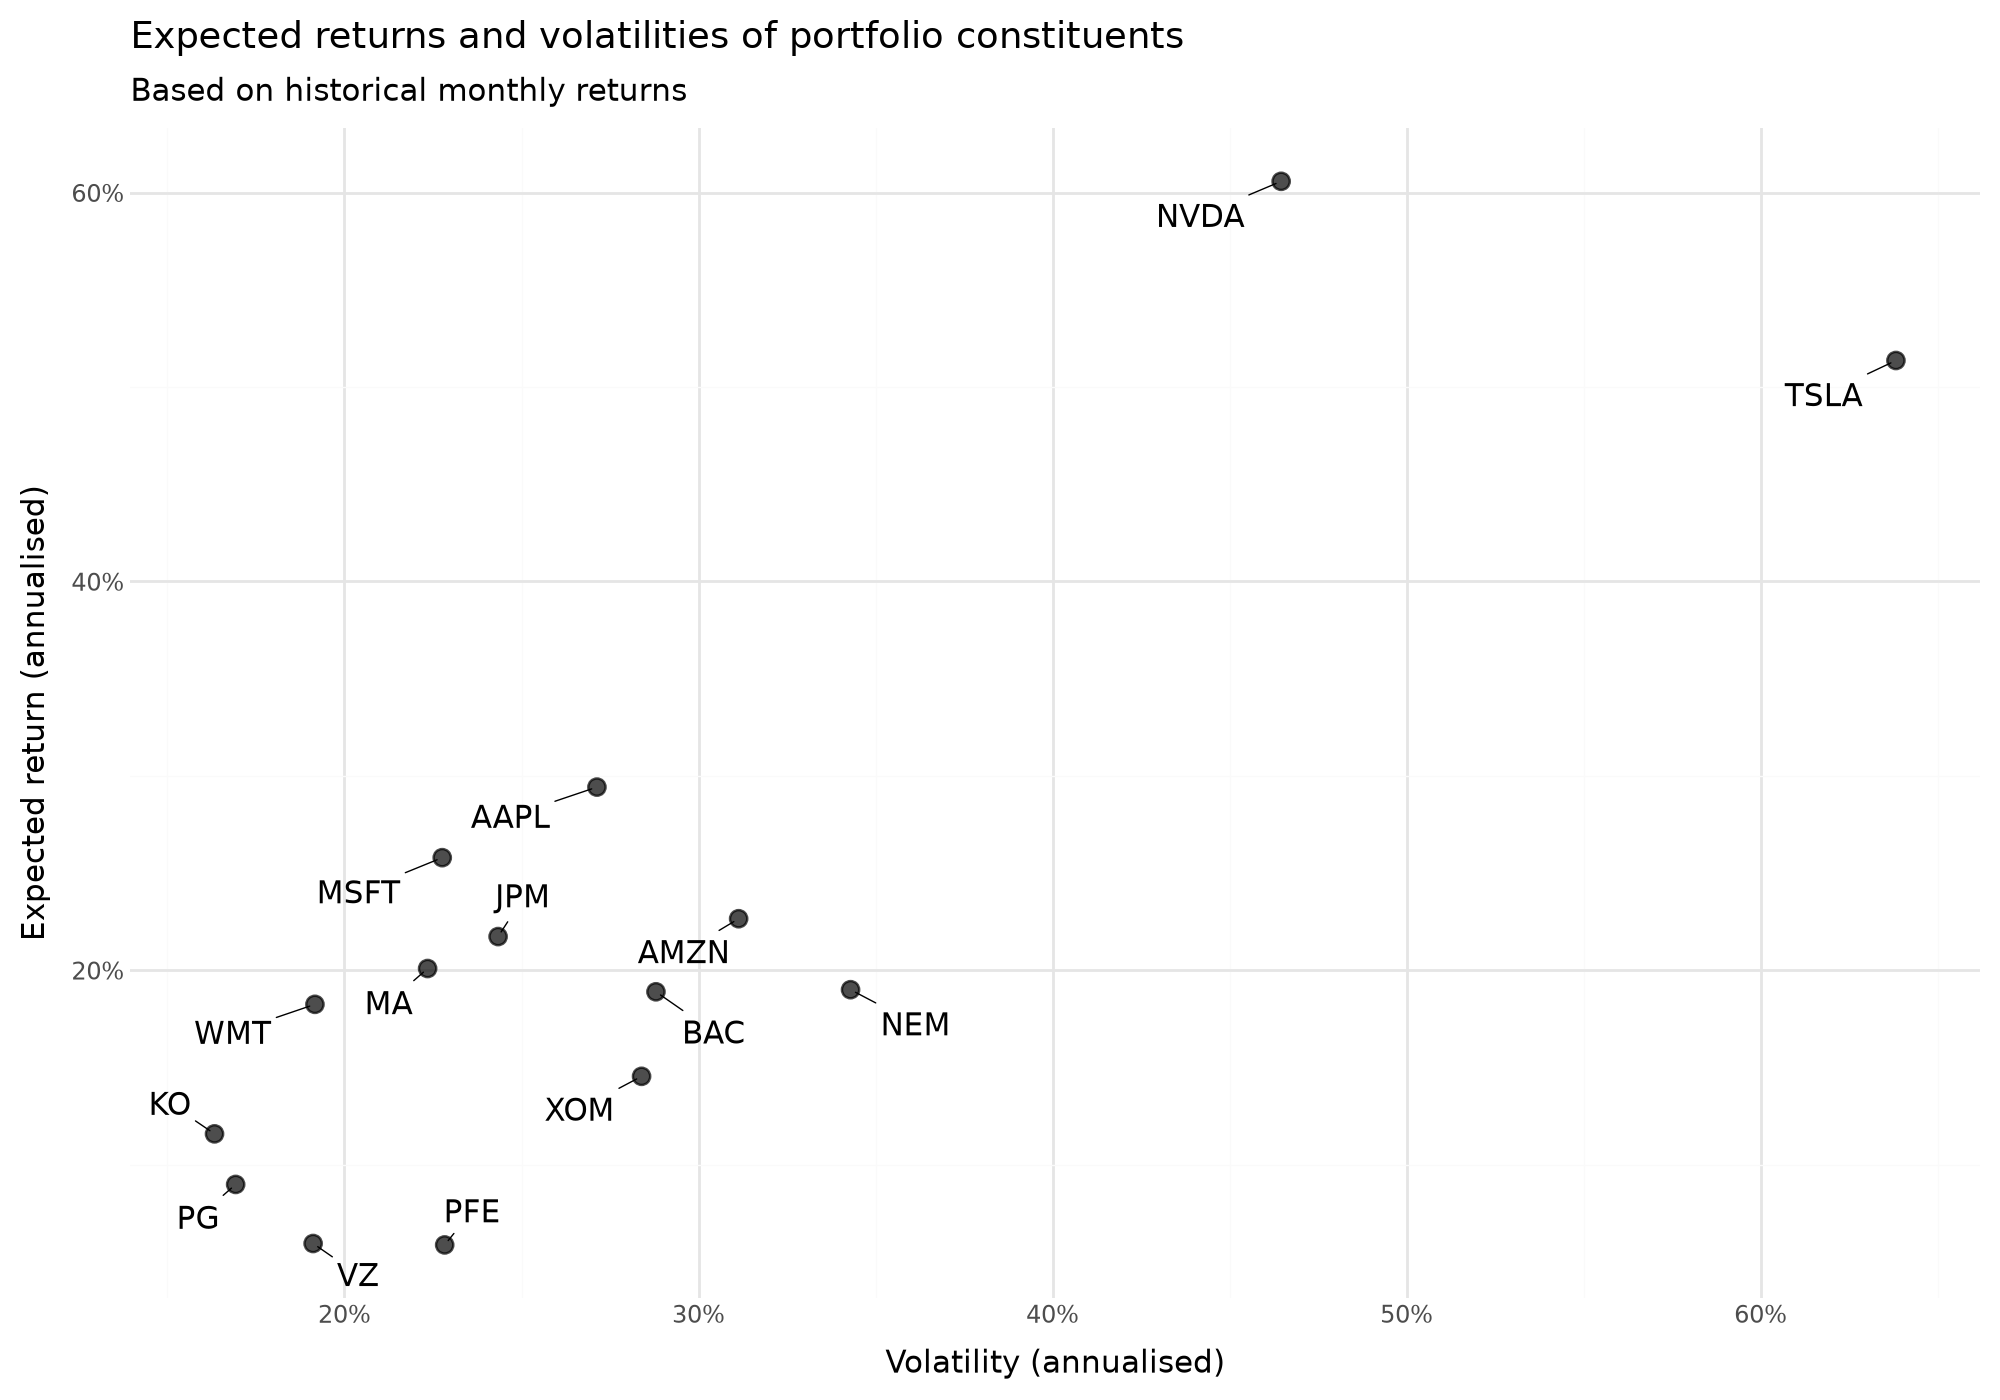

In [80]:
# Visualising the risk-return tradeoff
# Create asset summary with expected returns and volatilities
asset_summary = pd.DataFrame(
    {
        "symbol": summary_stats["symbol"],  # Stock ticker symbols
        "mu": summary_stats["mean"] * annualisation_factor,  # Arithmetic annualised mean
        "sigma": summary_stats["std"]
        * np.sqrt(annualisation_factor),  # Annualized volatility
    }
).reset_index(drop=True)

# Create enhanced scatter plot with better text positioning
assets_figure = (
    # Initialize plot with data and aesthetic mappings
    ggplot(asset_summary, aes(x="sigma", y="mu", label="symbol"))
    # Add points for each asset
    + geom_point(size=3, alpha=0.7)
    # Add text labels with automatic adjustment to prevent overlap
    + geom_text(adjust_text={"arrowprops": {"arrowstyle": "-"}})
    # Format x-axis as percentages
    + scale_x_continuous(labels=percent_format())
    # Format y-axis as percentages
    + scale_y_continuous(labels=percent_format())
    # Add informative labels
    + labs(
        x="Volatility (annualised)",
        y="Expected return (annualised)",
        title="Expected returns and volatilities of portfolio constituents",
        subtitle="Based on historical monthly returns",
    )
    # Use clean, professional theme
    + theme_minimal()
    # Set custom figure size
    + theme(figure_size=(10, 7))
)
# Display the plot
assets_figure

In [82]:
# Estimating expected returns using the above graph
# Use the same monthly observations as the summary and scatter plot.
mu = expected_returns.mean_historical_return(
    returns_wide, returns_data=True, compounding=False,
    frequency=annualisation_factor,
)
pd.DataFrame({"expected_return": mu}).T

,AAPL,AMZN,BAC,JPM,KO,MA,MSFT,NEM,NVDA,PFE,PG,TSLA,VZ,WMT,XOM
expected_return,0.294211,0.2265,0.188909,0.217315,0.115831,0.200884,0.257909,0.189987,0.605828,0.058698,0.089811,0.513657,0.059425,0.182458,0.145424


In [83]:
# Look at how the stocks move together by calculating a sample covariance matrix (annualised)
# This captures both individual asset volatilities and co-movements between assets
cov_matrix = risk_models.sample_cov(
    returns_wide, returns_data=True, frequency=annualisation_factor
)
# Display the covariance matrix
cov_matrix

,AAPL,AMZN,BAC,JPM,KO,MA,MSFT,NEM,NVDA,PFE,PG,TSLA,VZ,WMT,XOM
AAPL,0.073606,0.044924,0.024642,0.016225,0.010032,0.027710,0.033680,0.006667,0.064080,0.016145,0.012186,0.090579,0.005855,0.013773,0.011221
AMZN,0.044924,0.096922,0.029623,0.018687,0.001775,0.027720,0.046513,0.003506,0.081227,0.007322,0.000549,0.085490,0.005082,0.015690,0.006617
BAC,0.024642,0.029623,0.082927,0.063630,0.013880,0.032602,0.021529,-0.002940,0.047703,0.012080,0.008017,0.042667,0.011299,0.012465,0.040756
JPM,0.016225,0.018687,0.063630,0.059236,0.012258,0.027347,0.017362,-0.001877,0.036269,0.011619,0.006448,0.026088,0.009471,0.011616,0.031920
KO,0.010032,0.001775,0.013880,0.012258,0.026663,0.017907,0.007262,0.017077,-0.001055,0.009489,0.017669,0.003374,0.013587,0.010631,0.015410
MA,0.027710,0.027720,0.032602,0.027347,0.017907,0.049942,0.021716,0.003361,0.030595,0.008750,0.012626,0.033960,0.011653,0.010948,0.028152
MSFT,0.033680,0.046513,0.021529,0.017362,0.007262,0.021716,0.051806,0.005966,0.060543,0.009130,0.006131,0.049737,0.009802,0.009189,0.007078
NEM,0.006667,0.003506,-0.002940,-0.001877,0.017077,0.003361,0.005966,0.117607,-0.007271,0.024798,0.016175,0.028589,0.022096,0.009386,0.008248
NVDA,0.064080,0.081227,0.047703,0.036269,-0.001055,0.030595,0.060543,-0.007271,0.215816,0.013831,-0.000607,0.100264,0.008012,0.019667,0.013806
PFE,0.016145,0.007322,0.012080,0.011619,0.009489,0.008750,0.009130,0.024798,0.013831,0.052120,0.008946,0.012734,0.013584,0.008406,0.012761


In [86]:
# Long only efficient frontier and portfolios
# Initialize with expected returns (mu) and covariance matrix
ef_sharpe = EfficientFrontier(mu, cov_matrix)

# Maximum Sharpe ratio portfolio (tangency portfolio)
# This solves: max (mu_p - r_f) / sigma_p with the illustrative annual r_f = 2%
max_sharpe_weights = ef_sharpe.max_sharpe(risk_free_rate=risk_free_rate)
# Clean weights: remove tiny positions (below threshold) for practical implementation
cleaned_max_sharpe = ef_sharpe.clean_weights()
# Calculate portfolio performance metrics (expected return, volatility, Sharpe ratio)
max_sharpe_perf = ef_sharpe.portfolio_performance(verbose=True, risk_free_rate=risk_free_rate)

print("\n" + "=" * 50)
print("MAXIMUM SHARPE RATIO PORTFOLIO")
print("=" * 50)
# Convert weights dictionary to DataFrame and sort by weight size
max_sharpe_weights_df = (
    pd.Series(cleaned_max_sharpe, name="weight").sort_values(ascending=False).to_frame()
)
# Create metrics series for cleaner display
max_sharpe_metrics = pd.Series(
    max_sharpe_perf,
    index=["expected_return", "volatility", "sharpe_ratio"],
    name="max_sharpe_portfolio",
)
print("Portfolio weights:")
print(max_sharpe_weights_df)
print(f"\nPerformance metrics:")
print(max_sharpe_metrics)

Expected annual return: 29.2%
Annual volatility: 17.6%
Sharpe Ratio: 1.55

MAXIMUM SHARPE RATIO PORTFOLIO
Portfolio weights:
       weight
NVDA  0.21665
WMT   0.21109
KO    0.12958
NEM   0.12599
JPM   0.10657
MSFT  0.08598
AAPL  0.05390
TSLA  0.03089
XOM   0.02304
MA    0.01628
BAC   0.00000
AMZN  0.00000
PFE   0.00000
PG    0.00000
VZ    0.00000

Performance metrics:
expected_return    0.292402
volatility         0.175574
sharpe_ratio       1.551493
Name: max_sharpe_portfolio, dtype: float64


In [87]:
# Now find the minimum volatility portfolio weights where no short selling is allowed
# Create a fresh EfficientFrontier object (each optimization needs its own instance)
ef_min_vol = EfficientFrontier(mu, cov_matrix)
# Optimize for minimum volatility (ignores expected returns)
min_vol_weights = ef_min_vol.min_volatility()
# Clean up small weights for practical implementation
cleaned_min_vol = ef_min_vol.clean_weights()
# Calculate performance metrics
min_vol_perf = ef_min_vol.portfolio_performance(verbose=True, risk_free_rate=risk_free_rate)

print("\n" + "=" * 50)
print("MINIMUM VOLATILITY PORTFOLIO")
print("=" * 50)
# Convert weights to DataFrame and sort
min_vol_weights_df = (
    pd.Series(cleaned_min_vol, name="weight").sort_values(ascending=False).to_frame()
)
# Create metrics series
min_vol_metrics = pd.Series(
    min_vol_perf,
    index=["expected_return", "volatility", "sharpe_ratio"],
    name="min_vol_portfolio",
)
print("Portfolio weights:")
print(min_vol_weights_df)
print(f"\nPerformance metrics:")
print(min_vol_metrics)

Expected annual return: 13.6%
Annual volatility: 12.2%
Sharpe Ratio: 0.95

MINIMUM VOLATILITY PORTFOLIO
Portfolio weights:
       weight
PG    0.19153
KO    0.18936
WMT   0.14836
PFE   0.11483
MSFT  0.10433
VZ    0.09859
JPM   0.05185
XOM   0.04663
AMZN  0.04645
NEM   0.00807
AAPL  0.00000
MA    0.00000
BAC   0.00000
NVDA  0.00000
TSLA  0.00000

Performance metrics:
expected_return    0.135816
volatility         0.121539
sharpe_ratio       0.952913
Name: min_vol_portfolio, dtype: float64


In [93]:
# Now comparing the long-only position to one with short-selling allowed
print("=" * 60)
print("COMPARING BOUNDED SHORT-SELLING VS. LONG-ONLY PORTFOLIOS")
print("=" * 60)

# =============================================================================
# BOUNDED SHORT-SELLING PORTFOLIOS (Allow short-selling)
# =============================================================================
print("\n" + "=" * 60)
print("BOUNDED SHORT-SELLING PORTFOLIOS (SHORT-SELLING ALLOWED)")
print("=" * 60)

# Maximum Sharpe with short-selling allowed
# weight_bounds=(-1, 1) means: -100% ≤ weight ≤ +100% for each asset
# Negative weights = short positions, Positive weights = long positions
ef_bounded_short_sharpe = EfficientFrontier(mu, cov_matrix, weight_bounds=(-1, 1))
# Optimize for maximum Sharpe ratio
bounded_short_sharpe_weights = ef_bounded_short_sharpe.max_sharpe(risk_free_rate=risk_free_rate)
# Clean weights (removes positions below threshold)
cleaned_bounded_short_sharpe = ef_bounded_short_sharpe.clean_weights()
# Calculate performance metrics
bounded_short_sharpe_perf = ef_bounded_short_sharpe.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

print("\nMaximum Sharpe Portfolio (Bounded short-selling):")
bounded_short_sharpe_df = (
    pd.Series(cleaned_bounded_short_sharpe, name="weight")
    .sort_values(ascending=False)
    .to_frame()
)
print("Weights:")
print(bounded_short_sharpe_df)
print(f"\nExpected Return: {bounded_short_sharpe_perf[0]:.4f}")
print(f"Volatility: {bounded_short_sharpe_perf[1]:.4f}")
print(f"Sharpe Ratio: {bounded_short_sharpe_perf[2]:.4f}")

# Count short positions
num_shorts = sum(1 for w in cleaned_bounded_short_sharpe.values() if w < 0)
num_longs = sum(1 for w in cleaned_bounded_short_sharpe.values() if w > 0)
print(f"\nShort positions: {num_shorts} assets")
print(f"Long positions: {num_longs} assets")

# Minimum volatility with short-selling allowed
ef_bounded_short_minvol = EfficientFrontier(mu, cov_matrix, weight_bounds=(-1, 1))
# Optimize for minimum volatility
bounded_short_minvol_weights = ef_bounded_short_minvol.min_volatility()
# Clean weights
cleaned_bounded_short_minvol = ef_bounded_short_minvol.clean_weights()
# Calculate performance
bounded_short_minvol_perf = ef_bounded_short_minvol.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

print("\nMinimum Volatility Portfolio (Bounded short-selling):")
bounded_short_minvol_df = (
    pd.Series(cleaned_bounded_short_minvol, name="weight")
    .sort_values(ascending=False)
    .to_frame()
)
print("Weights:")
print(bounded_short_minvol_df)
print(f"\nExpected Return: {bounded_short_minvol_perf[0]:.4f}")
print(f"Volatility: {bounded_short_minvol_perf[1]:.4f}")
print(f"Sharpe Ratio: {bounded_short_minvol_perf[2]:.4f}")

# Count short positions
num_shorts_mv = sum(1 for w in cleaned_bounded_short_minvol.values() if w < 0)
num_longs_mv = sum(1 for w in cleaned_bounded_short_minvol.values() if w > 0)
print(f"\nShort positions: {num_shorts_mv} assets")
print(f"Long positions: {num_longs_mv} assets")

# =============================================================================
# LONG-ONLY PORTFOLIOS (No short-selling)
# =============================================================================
print("\n" + "=" * 60)
print("LONG-ONLY PORTFOLIOS (NO SHORT-SELLING)")
print("=" * 60)

# Maximum Sharpe with long-only constraint
# weight_bounds=(0, 1) means: 0 ≤ weight ≤ 1 for each asset (no shorts, no leverage)
ef_long_only = EfficientFrontier(mu, cov_matrix, weight_bounds=(0, 1))
# Optimize for maximum Sharpe ratio
long_only_sharpe_weights = ef_long_only.max_sharpe(risk_free_rate=risk_free_rate)
# Clean weights (removes positions below threshold)
cleaned_long_only_sharpe = ef_long_only.clean_weights()
# Calculate performance metrics
long_only_sharpe_perf = ef_long_only.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

print("\nMaximum Sharpe Portfolio (Long-only):")
long_only_sharpe_df = (
    pd.Series(cleaned_long_only_sharpe, name="weight")
    .sort_values(ascending=False)
    .to_frame()
)
print("Weights:")
print(long_only_sharpe_df)
print(f"\nExpected Return: {long_only_sharpe_perf[0]:.4f}")
print(f"Volatility: {long_only_sharpe_perf[1]:.4f}")
print(f"Sharpe Ratio: {long_only_sharpe_perf[2]:.4f}")

# Minimum volatility with long-only constraint
ef_long_only_minvol = EfficientFrontier(mu, cov_matrix, weight_bounds=(0, 1))
# Optimize for minimum volatility
long_only_minvol_weights = ef_long_only_minvol.min_volatility()
# Clean weights
cleaned_long_only_minvol = ef_long_only_minvol.clean_weights()
# Calculate performance
long_only_minvol_perf = ef_long_only_minvol.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

print("\nMinimum Volatility Portfolio (Long-only):")
long_only_minvol_df = (
    pd.Series(cleaned_long_only_minvol, name="weight")
    .sort_values(ascending=False)
    .to_frame()
)
print("Weights:")
print(long_only_minvol_df)
print(f"\nExpected Return: {long_only_minvol_perf[0]:.4f}")
print(f"Volatility: {long_only_minvol_perf[1]:.4f}")
print(f"Sharpe Ratio: {long_only_minvol_perf[2]:.4f}")

# =============================================================================
# COMPARISON: Cost of constraints
# =============================================================================
print("\n" + "=" * 60)
print("IMPACT OF SHORT-SELLING CONSTRAINT")
print("=" * 60)

print("\nMaximum Sharpe Portfolio:")
print(
    f"  Bounded short-selling - Sharpe: {bounded_short_sharpe_perf[2]:.4f}, Vol: {bounded_short_sharpe_perf[1]:.4f}"
)
print(
    f"  Long-only     - Sharpe: {long_only_sharpe_perf[2]:.4f}, Vol: {long_only_sharpe_perf[1]:.4f}"
)
sharpe_loss = (
    (bounded_short_sharpe_perf[2] - long_only_sharpe_perf[2])
    / bounded_short_sharpe_perf[2]
) * 100
print(f"  → Sharpe ratio reduction: {sharpe_loss:.1f}%")

print("\nMinimum Volatility Portfolio:")
print(
    f"  Bounded short-selling - Vol: {bounded_short_minvol_perf[1]:.4f}, Return: {bounded_short_minvol_perf[0]:.4f}"
)
print(
    f"  Long-only     - Vol: {long_only_minvol_perf[1]:.4f}, Return: {long_only_minvol_perf[0]:.4f}"
)
vol_increase = (
    (long_only_minvol_perf[1] - bounded_short_minvol_perf[1])
    / bounded_short_minvol_perf[1]
) * 100
print(f"  → Volatility increase: {vol_increase:.1f}%")

COMPARING BOUNDED SHORT-SELLING VS. LONG-ONLY PORTFOLIOS

BOUNDED SHORT-SELLING PORTFOLIOS (SHORT-SELLING ALLOWED)

Maximum Sharpe Portfolio (Bounded short-selling):
Weights:
       weight
JPM   0.73409
WMT   0.30990
NVDA  0.27723
MSFT  0.23676
NEM   0.20309
KO    0.19763
AAPL  0.16006
XOM   0.14139
MA    0.04994
TSLA  0.04369
PG   -0.05563
AMZN -0.20281
PFE  -0.22649
VZ   -0.24863
BAC  -0.62023

Expected Return: 0.4105
Volatility: 0.2193
Sharpe Ratio: 1.7805

Short positions: 5 assets
Long positions: 10 assets

Minimum Volatility Portfolio (Bounded short-selling):
Weights:
       weight
JPM   0.25744
PG    0.20871
KO    0.19219
WMT   0.13140
MSFT  0.10592
PFE   0.10571
VZ    0.09218
AMZN  0.08748
XOM   0.07576
AAPL  0.00552
TSLA  0.00027
NEM  -0.00020
NVDA -0.01730
MA   -0.05051
BAC  -0.19457

Expected Return: 0.1351
Volatility: 0.1191
Sharpe Ratio: 0.9666

Short positions: 4 assets
Long positions: 11 assets

LONG-ONLY PORTFOLIOS (NO SHORT-SELLING)

Maximum Sharpe Portfolio (Long-only

In [94]:
# Minimum volatility portfolio with bounded short-selling
# Create a fresh EfficientFrontier object (each optimization needs its own instance)
ef_min_vol = EfficientFrontier(mu, cov_matrix, weight_bounds=(-1, 1))
# Optimize for minimum volatility (ignores expected returns)
min_vol_weights = ef_min_vol.min_volatility()
# Clean up small weights for practical implementation
cleaned_min_vol = ef_min_vol.clean_weights()
# Calculate performance metrics
min_vol_perf = ef_min_vol.portfolio_performance(verbose=True, risk_free_rate=risk_free_rate)

print("\n" + "=" * 50)
print("MINIMUM VOLATILITY PORTFOLIO (BOUNDED SHORT-SELLING)")
print("=" * 50)
# Convert weights to DataFrame and sort
min_vol_weights_df = (
    pd.Series(cleaned_min_vol, name="weight").sort_values(ascending=False).to_frame()
 )
# Create metrics series
min_vol_metrics = pd.Series(
    min_vol_perf,
    index=["expected_return", "volatility", "sharpe_ratio"],
    name="min_vol_portfolio",
)
print("Portfolio weights:")
print(min_vol_weights_df)
print(f"\nPerformance metrics:")
print(min_vol_metrics)

Expected annual return: 13.5%
Annual volatility: 11.9%
Sharpe Ratio: 0.97

MINIMUM VOLATILITY PORTFOLIO (BOUNDED SHORT-SELLING)
Portfolio weights:
       weight
JPM   0.25744
PG    0.20871
KO    0.19219
WMT   0.13140
MSFT  0.10592
PFE   0.10571
VZ    0.09218
AMZN  0.08748
XOM   0.07576
AAPL  0.00552
TSLA  0.00027
NEM  -0.00020
NVDA -0.01730
MA   -0.05051
BAC  -0.19457

Performance metrics:
expected_return    0.135098
volatility         0.119073
sharpe_ratio       0.966614
Name: min_vol_portfolio, dtype: float64


In [95]:
# Set a target return (clipped to feasible range for safety)
target_return = float(np.clip(mu.mean(), mu.min(), mu.max()))
# Create fresh EfficientFrontier object
ef_target = EfficientFrontier(mu, cov_matrix)
# Optimize to achieve target return with minimum risk
target_weights = ef_target.efficient_return(target_return=target_return)
# Clean weights
cleaned_target = ef_target.clean_weights()
# Calculate performance (verbose=False to suppress output)
target_perf = ef_target.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

# Convert to DataFrames for display
target_weights_df = (
    pd.Series(cleaned_target, name="weight").sort_values(ascending=False).to_frame()
)
target_metrics = pd.Series(
    target_perf,
    index=["expected_return", "volatility", "sharpe_ratio"],
    name=f"target_return_{target_return:.2%}",
)
# Display weights and metrics
target_weights_df, target_metrics

(       weight
 WMT   0.21785
 KO    0.20130
 MSFT  0.14164
 NVDA  0.09433
 JPM   0.09082
 NEM   0.08580
 PG    0.06641
 XOM   0.05042
 AAPL  0.04270
 TSLA  0.00873
 AMZN  0.00000
 MA    0.00000
 BAC   0.00000
 PFE   0.00000
 VZ    0.00000,
 expected_return    0.223123
 volatility         0.139167
 sharpe_ratio       1.459565
 Name: target_return_22.31%, dtype: float64)

In [96]:
def compute_frontier_points(mu_vec, cov, weight_bounds):
    """Trace the efficient upper branch under the specified position bounds."""
    minimum = EfficientFrontier(mu_vec, cov, weight_bounds=weight_bounds)
    minimum.min_volatility()
    minimum_return = minimum.portfolio_performance(
        risk_free_rate=risk_free_rate
    )[0]

    # Maximise a linear expected return subject to the same position bounds.
    weights = cp.Variable(len(mu_vec))
    maximum = cp.Problem(cp.Maximize(mu_vec.to_numpy() @ weights), [
        cp.sum(weights) == 1,
        weights >= weight_bounds[0], weights <= weight_bounds[1],
    ])
    maximum.solve(solver=cp.OSQP, max_iter=100_000)
    if maximum.status not in {cp.OPTIMAL, cp.OPTIMAL_INACCURATE}:
        raise RuntimeError(f"Maximum-return calculation failed: {maximum.status}")

    target_margin = max(1e-4, abs(float(maximum.value)) * 1e-4)
    targets = np.linspace(minimum_return, float(maximum.value) - target_margin, 25)
    rows = []
    for target in targets:
        ef = EfficientFrontier(
            mu_vec,
            cov,
            weight_bounds=weight_bounds,
            solver=cp.OSQP,
            solver_options={"max_iter": 100_000},
        )
        ef.efficient_return(float(target))
        perf = ef.portfolio_performance(risk_free_rate=risk_free_rate)
        rows.append({"target_return": target, "expected_return": perf[0],
                     "volatility": perf[1], "sharpe_ratio": perf[2]})
    return pd.DataFrame(rows)


frontier_bounded_short = compute_frontier_points(mu, cov_matrix, (-1, 1))
frontier_long_only = compute_frontier_points(mu, cov_matrix, (0, 1))
frontier_bounded_short["constraint_type"] = "Bounded short-selling"
frontier_long_only["constraint_type"] = "Long-only"
all_frontiers = pd.concat([frontier_bounded_short, frontier_long_only], ignore_index=True)

# Individual asset positions (for reference on plot)
asset_positions = pd.DataFrame(
    {
        "symbol": mu.index,
        "expected_return": mu,
        "volatility": np.sqrt(np.diag(cov_matrix)),  # Square root of variance
    }
).reset_index(drop=True)

# Key portfolios with different constraints (for annotation on plot)
key_portfolios = pd.DataFrame(
    [
        {
            "portfolio": "Min vol (short)",
            "expected_return": bounded_short_minvol_perf[0],
            "volatility": bounded_short_minvol_perf[1],
            "constraint_type": "Bounded short-selling",
        },
        {
            "portfolio": "Max Sharpe (short)",
            "expected_return": bounded_short_sharpe_perf[0],
            "volatility": bounded_short_sharpe_perf[1],
            "constraint_type": "Bounded short-selling",
        },
        {
            "portfolio": "Target (Long-only)",
            "expected_return": target_perf[0],
            "volatility": target_perf[1],
            "constraint_type": "Long-only",
        },
        {
            "portfolio": "Min Vol (Long-only)",
            "expected_return": long_only_minvol_perf[0],
            "volatility": long_only_minvol_perf[1],
            "constraint_type": "Long-only",
        },
        {
            "portfolio": "Max Sharpe (Long-only)",
            "expected_return": long_only_sharpe_perf[0],
            "volatility": long_only_sharpe_perf[1],
            "constraint_type": "Long-only",
        },
    ]
).reset_index(drop=True)

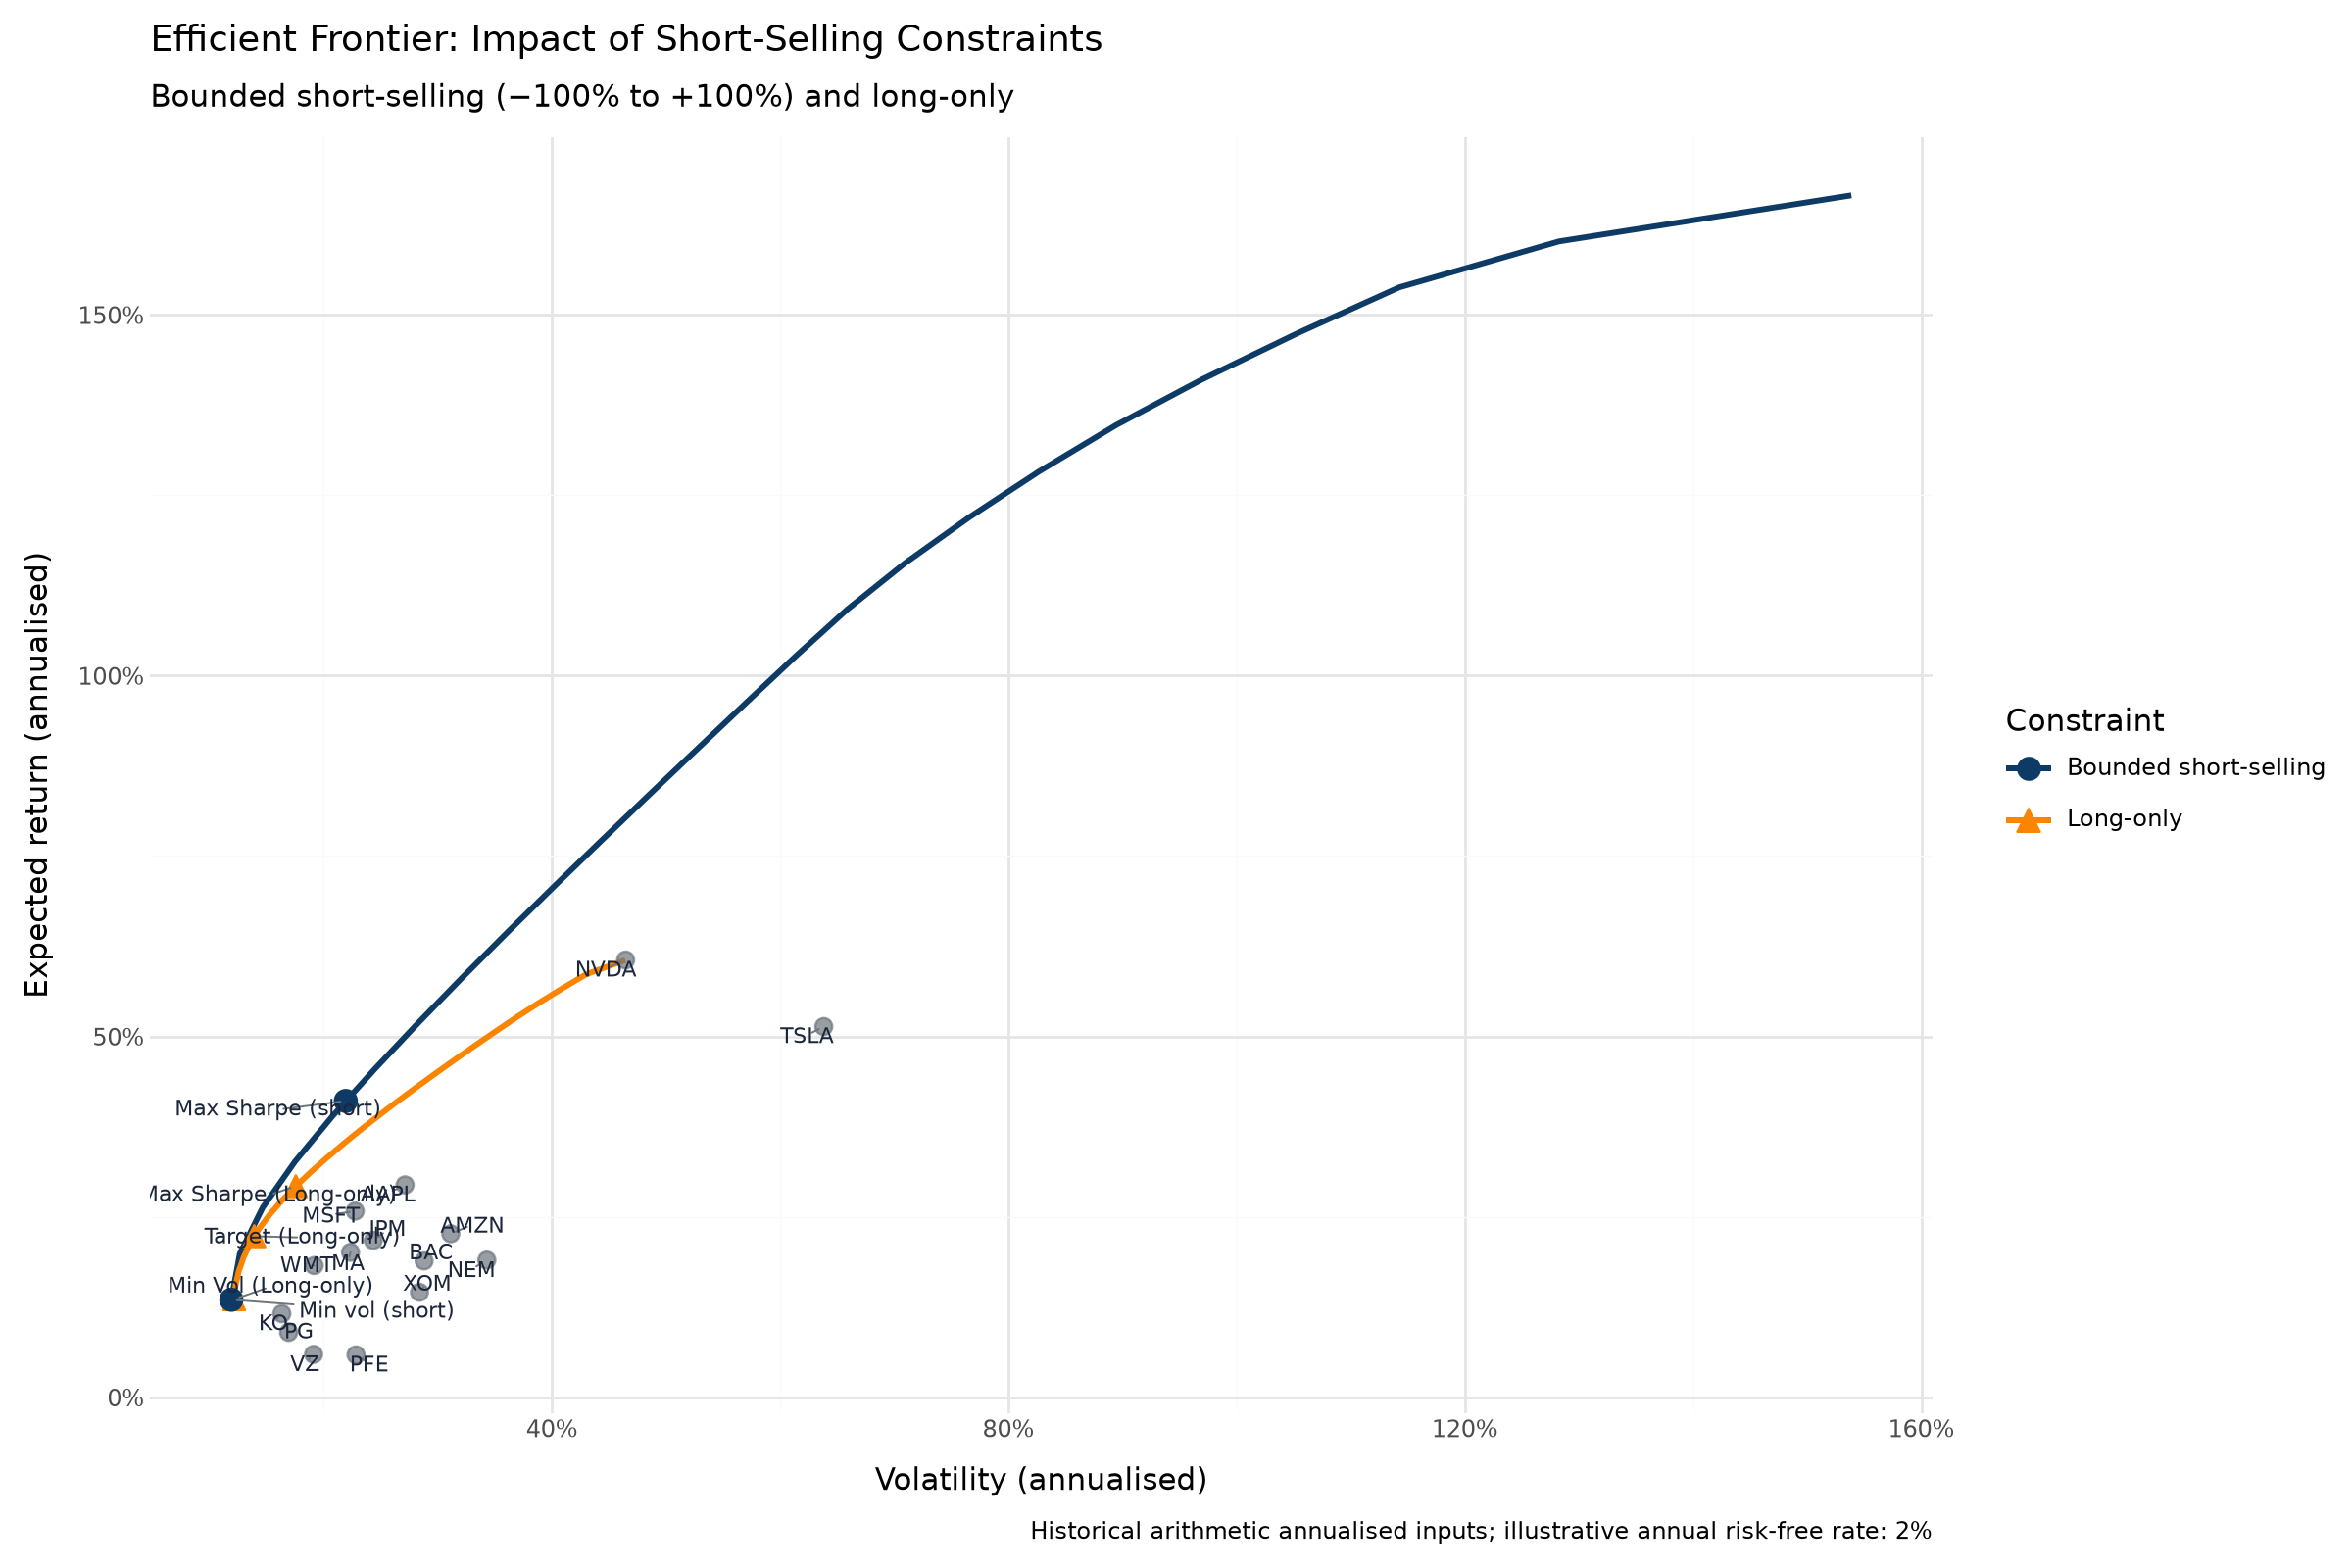

In [97]:
# Adjust all labels together so asset and portfolio labels avoid each other.
plot_labels = pd.concat([
    asset_positions.rename(columns={"symbol": "label"}),
    key_portfolios.rename(columns={"portfolio": "label"}),
], ignore_index=True)
np.random.seed(3318)  # Reproducible initial displacement of overlapping labels

enhanced_plot = (
    ggplot()
    + geom_line(
        all_frontiers,
        aes(x="volatility", y="expected_return", color="constraint_type"),
        size=1.2,
    )
    + geom_point(
        asset_positions, aes(x="volatility", y="expected_return"),
        color="#6c757d", size=3, alpha=0.7,
    )
    + geom_point(
        key_portfolios,
        aes(x="volatility", y="expected_return", color="constraint_type",
            shape="constraint_type"), size=4,
    )
    + geom_text(
        plot_labels, aes(x="volatility", y="expected_return", label="label"),
        size=8, color="#1b263b",
        adjust_text={
            "arrowprops": {"arrowstyle": "-", "color": "#6c757d", "lw": 0.7},
            "expand": (1.3, 1.5), "force_text": (0.6, 0.9),
            "force_static": (0.4, 0.5), "force_pull": (0.005, 0.005),
            "iter_lim": 1000,
        },
    )
    + scale_x_continuous(labels=percent_format())
    + scale_y_continuous(labels=percent_format())
    + scale_color_manual(values={"Bounded short-selling": "#0d3b66", "Long-only": "#fb8500"})
    + scale_shape_manual(values={"Bounded short-selling": "o", "Long-only": "^"})
    + labs(
        title="Efficient Frontier: Impact of Short-Selling Constraints",
        subtitle="Bounded short-selling (−100% to +100%) and long-only",
        x="Volatility (annualised)", y="Expected return (annualised)",
        color="Constraint", shape="Constraint",
        caption="Historical arithmetic annualised inputs; illustrative annual risk-free rate: 2%",
    )
    + theme_minimal()
    + theme(figure_size=(12, 8))
)
enhanced_plot


PORTFOLIO WEIGHTS COMPARISON
Portfolio weights summary:
      Max Sharpe (Short)  Min Vol (Short)  Max Sharpe (Long)  Min Vol (Long)
AAPL             0.16006          0.00552            0.05390         0.00000
AMZN            -0.20281          0.08748            0.00000         0.04645
BAC             -0.62023         -0.19457            0.00000         0.00000
JPM              0.73409          0.25744            0.10657         0.05185
KO               0.19763          0.19219            0.12958         0.18936
MA               0.04994         -0.05051            0.01628         0.00000
MSFT             0.23676          0.10592            0.08598         0.10433
NEM              0.20309         -0.00020            0.12599         0.00807
NVDA             0.27723         -0.01730            0.21665         0.00000
PFE             -0.22649          0.10571            0.00000         0.11483
PG              -0.05563          0.20871            0.00000         0.19153
TSLA             0.

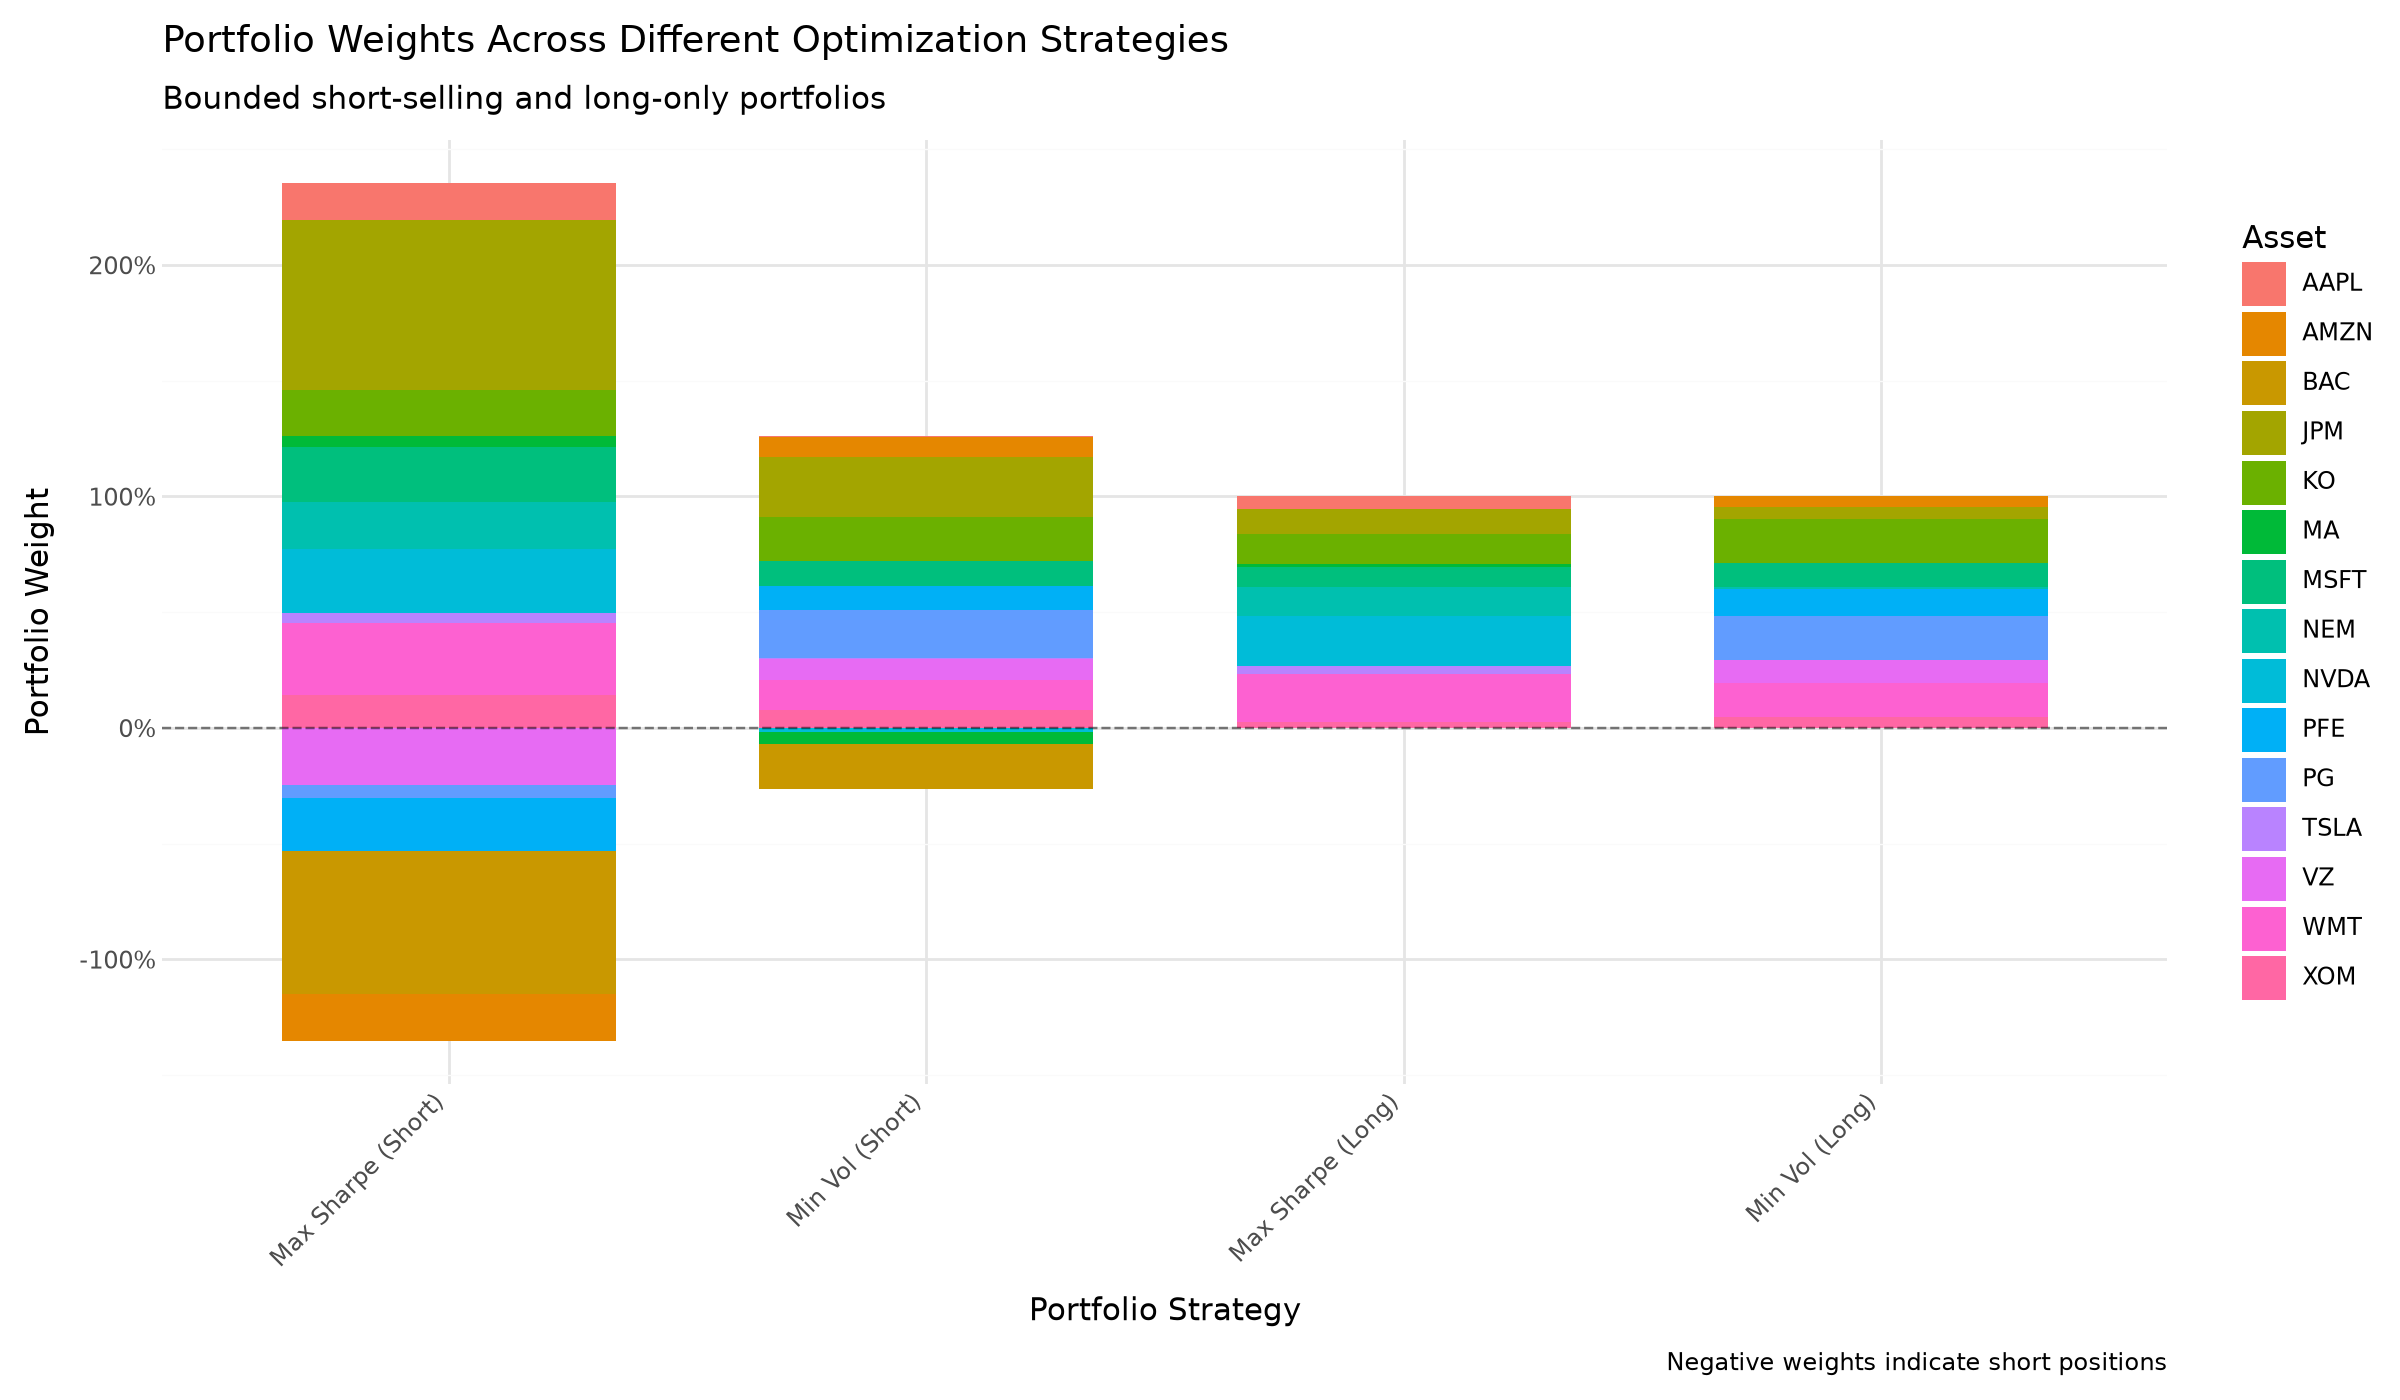

In [98]:
# Portfolio weights comparison visualization
print("\n" + "=" * 50)
print("PORTFOLIO WEIGHTS COMPARISON")
print("=" * 50)

# Compile all portfolio weights (excluding custom constraints for now)
# Each column represents one portfolio strategy
weights_comparison = pd.DataFrame(
    {
        "Max Sharpe (Short)": pd.Series(
            cleaned_bounded_short_sharpe
        ),  # Maximum Sharpe, bounded_short
        "Min Vol (Short)": pd.Series(
            cleaned_bounded_short_minvol
        ),  # Minimum volatility, bounded_short
        "Max Sharpe (Long)": pd.Series(
            cleaned_long_only_sharpe
        ),  # Maximum Sharpe, long-only
        "Min Vol (Long)": pd.Series(
            cleaned_long_only_minvol
        ),  # Minimum volatility, long-only
    }
).fillna(
    0
)  # Replace NaN with 0 (assets not included in portfolio)

print("Portfolio weights summary:")
print(weights_comparison)

# Create stacked bar chart with better styling
# Reshape data from wide to long format for ggplot
weights_long = (
    weights_comparison.reset_index()
    .melt(id_vars="index", var_name="Portfolio", value_name="Weight")
    .rename(columns={"index": "Asset"})
)

# Add constraint type for coloring
weights_long["Constraint_Type"] = weights_long["Portfolio"].apply(
    lambda x: "Long-only" if "Long" in x else "Bounded short-selling"
)

# Sort portfolios for better display (explicit ordering)
weights_long["Portfolio"] = pd.Categorical(
    weights_long["Portfolio"],
    categories=[
        "Max Sharpe (Short)",
        "Min Vol (Short)",
        "Max Sharpe (Long)",
        "Min Vol (Long)",
    ],
    ordered=True,
)

# Create stacked bar chart
weights_plot = (
    ggplot(weights_long, aes(x="Portfolio", y="Weight", fill="Asset"))
    # Stacked bars showing composition of each portfolio
    + geom_col(position="stack", width=0.7)
    # Add horizontal line at zero to clearly show short positions
    + geom_hline(yintercept=0, linetype="dashed", color="black", alpha=0.5)
    # Format y-axis as percentages
    + scale_y_continuous(labels=percent_format())
    # Add comprehensive labels
    + labs(
        title="Portfolio Weights Across Different Optimization Strategies",
        subtitle="Bounded short-selling and long-only portfolios",
        x="Portfolio Strategy",
        y="Portfolio Weight",
        caption="Negative weights indicate short positions",
    )
    # Use minimal theme
    + theme_minimal()
    # Rotate x-axis labels for readability
    + theme(
        axis_text_x=element_text(angle=45, hjust=1),
        figure_size=(12, 7),
        legend_position="right",
    )
    # Customize legend
    + guides(fill=guide_legend(title="Asset"))
)

# Display the plot
weights_plot